# Assignment 2, Part 2: Pedestrians on Eindhoven Centraal

In this notebook you model the future motion of pedestrians on platforms 3 and 4 of Eindhoven Centraal. Given the first 10 observed frames of a scene, you generate the remaining 20 frames for all pedestrians using conditional flow matching with time bundling.

You implement and compare two models:
1. a model with an uninformed Gaussian prior on the future velocities;
2. a model with an informed, data dependent prior.

The focus is not on model performance, but on an architecture that fits the problem formulation and on the comparison between the two priors. Every group member must be able to explain the model design and interpret the results. The full task description is in Section 2 of the assignment PDF.

In [ ]:
import gdown
from pathlib import Path
import pickle
import torch
from torch.utils.data import Dataset
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import to_dense_batch
from torch import nn
import torch.nn.functional as F
import lightning as L
from lightning import LightningDataModule, LightningModule, Trainer
import math
import warnings
import matplotlib.pyplot as plt
import numpy as np

SEED = 42

## Dataset

The dataset contains 100,000 samples. Each sample is a scene with 5 to 100 pedestrians, stored as an array of shape `(N, 30, 2)`: the 2D positions in metres of `N` pedestrians over 30 frames, spaced $\Delta t = 0.5$ s apart (15 s in total). Every pedestrian is present in all 30 frames.

The cell below downloads the data (about 290 MB).

In [261]:
drive_link = "https://drive.google.com/file/d/1sU_gti1xg2AB_SQINy_cZZm4jxE9lbIm/view?usp=drive_link"

DATA_PATH = Path("eindhoven_centraal.pkl")

if not DATA_PATH.exists():

    print("Downloading dataset...")

    gdown.download(
        url=drive_link,
        output=str(DATA_PATH),
        quiet=False,
    )

    print(
        "Download complete:",
        DATA_PATH,
    )

else:
    print(
        "Dataset already available:",
        DATA_PATH,
    )

Dataset already available: eindhoven_centraal.pkl


## Data loading and graph construction

`PedestriansDataset` loads the samples and turns each one into a graph:

* **Nodes** are pedestrians. The node features `x` are the full trajectories, with shape `(N, 30, 2)`.
* **Edges** are fixed over time: the same `edge_index` of shape `(2, E)` is used for every frame. The example graph is fully connected without self loops, so $E = N(N-1)$.

After batching with the PyG `DataLoader`, `x` has shape `(sum N, 30, 2)`, the edges of each scene are offset so they never connect different scenes, and `batch` gives the scene index of every pedestrian.

A fully connected graph grows with $N^2$ and connects pedestrians that are far apart and do not interact. You can and should implement a less connected graph in `make_edge_index`, for example a radius or k nearest neighbour graph. Such a graph may only be built from the observed frames 0 to 9, since the target frames are not available at inference.

`GraphDataModule` splits the samples randomly at sample level with a fixed seed, so no scene appears in more than one split. The test set must contain at least 1,000 samples; a larger test set is preferred. Normalization statistics must be computed on the training split only.

In [262]:
T_cond = 10
DT = 0.5
n_samples = 25000
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

In [263]:
def edge_features(positions, edge_index):
    """Compute edge features for a artibitrarily connected graph given node features X and edge indices."""
    displacements = positions[edge_index[0]] - positions[edge_index[1]]
    unit_displacements = F.normalize(displacements, dim=-1)
    dists = torch.norm(displacements, dim=-1, keepdim=True)
    edge_attr = torch.cat([unit_displacements, dists], dim=-1)
    return edge_attr

class PedestriansDataset(Dataset):
    """Pedestrian scenes as graphs with an edge connectivity that is fixed over time.

    Every sample is one scene with N pedestrians over F = 30 frames. Nodes are pedestrians
    and the node features are their full trajectories:
        x:          (N, F, 2)   positions in metres
        edge_index: (2, E)      edges between pedestrians, shared by all frames

    After batching with the PyG DataLoader:
        x:          (sum N, F, 2)
        edge_index: (2, sum E)  offset per scene, so edges never cross scenes
        batch:      (sum N,)    scene index of every pedestrian
    """

    def __init__(self, path, n_samples=None, T_cond=10, k_neighbors = 5):
        self.T_cond = T_cond
        self.k_neighbors = k_neighbors
        self.raw_data = self._load_data(path)
        if n_samples is not None:
            self.raw_data = self.raw_data[:n_samples]
        print(f"Using {len(self.raw_data)} samples.")

    def _load_data(self, path):
        with open(path, "rb") as f:
            data = pickle.load(f)
        data = [torch.tensor(sample, dtype=torch.float32) for sample in data]
        print(
            f"\nLoaded {len(data)} samples from {path}, containing in total "
            f"{sum(x.shape[0] for x in data)} trajectories of {data[0].shape[1]} frames.\n"
        )
        return data

    def make_edge_index(self, sample, k_neighbors):
        """Artibitrarily connected graph between N pedestrians, without self loops."""

        # sample shape is N, 2
        
        N = sample.shape[0]

        if k_neighbors >= N:
            # fallback into fc graph
            # NOTE: A fully connected graph grows with N^2 and also connects pedestrians that are far
            # apart and do not interact. A less connected graph can and should be implemented here,
            # for example a radius graph or a k nearest neighbour graph. To avoid leaking information
            # about the future, such a graph may only be built from the observed frames 0 to T_cond - 1.
            
            not_self = ~torch.eye(N, dtype=torch.bool)  # True everywhere except the diagonal
            # print(f"kNN fallback triggered N is {N}")
            return not_self.nonzero().T.contiguous()
        else:
            #cap neighbors to k neighbors

            distances = torch.cdist(sample, sample) #N, N here
            distances = distances.fill_diagonal_(torch.inf)

            indices =[]
            for i in range(sample.shape[0]):
                topk = torch.topk(distances[i], k_neighbors, largest=False).indices
                current_index = torch.ones(k_neighbors, dtype=torch.float32) * i
                index_list = torch.stack((topk, current_index), dim=-1)
                indices.append(index_list)

            indices = torch.cat(indices, dim=0).long().T
            return indices


        

    def __len__(self):
        return len(self.raw_data)

    def __getitem__(self, idx):
        sample = self.raw_data[idx]
        N = sample.shape[0]
        T_cond = self.T_cond
        k_neighbors = self.k_neighbors

        sub_slice = sample[:, : T_cond, :]

        # The edge indices and attributes take the mean positions over frames 0 : T_cond to derive features
        mean_pos = torch.mean(sub_slice, dim=1)

        edge_index = self.make_edge_index(mean_pos, k_neighbors)
        edge_attr = edge_features(mean_pos, edge_index)

        return Data(x=sample, edge_index=edge_index, edge_attr=edge_attr, num_nodes=N)


class GraphDataModule(LightningDataModule):
    """Random split at sample level, so no scene appears in more than one split."""

    def __init__(self, dataset, train_split, val_split, test_split, batch_size=8, seed=SEED, min_test_size=1000):
        super().__init__()
        if not math.isclose(train_split + val_split + test_split, 1.0):
            raise ValueError("train_split, val_split and test_split must sum to 1.")
        self.batch_size = batch_size
        self.seed = seed
        self.train_data, self.val_data, self.test_data = self.split_data(dataset, train_split, val_split)
        self.T_cond = dataset.T_cond
        self.stats = self.calculate_stats(self.train_data, timestep_size=dt)

        print(
            f"Split with seed {seed}: {len(self.train_data)} train, "
            f"{len(self.val_data)} validation, {len(self.test_data)} test samples."
        )
        if len(self.test_data) < min_test_size:
            warnings.warn(
                f"The test set contains {len(self.test_data)} samples, "
                f"but the assignment requires at least {min_test_size}."
            )

    def split_data(self, dataset, train_split, val_split):
        total_size = len(dataset)
        train_size = int(total_size * train_split)
        val_size = int(total_size * val_split)
        test_size = total_size - train_size - val_size

        return torch.utils.data.random_split(
            dataset,
            [train_size, val_size, test_size],
            generator=torch.Generator().manual_seed(self.seed),
        )

    def calculate_stats(self, train_data, timestep_size = DT):
        T_cond = self.T_cond
        samples = [train_data.dataset.raw_data[i] for i in train_data.indices]

        pos = torch.cat([s[:, :T_cond, :].reshape(-1, 2) for s in samples], dim=0)
        pos_mean = pos.mean(dim=0)
        pos_std = pos.std(dim=0)

        vel = torch.cat(
            [(s[:, 1:T_cond, :] - s[:, :T_cond - 1, :]).reshape(-1, 2) for s in samples],
            dim=0,
        ) / timestep_size
        vel_mean = vel.mean(dim=0)
        vel_std = vel.std(dim=0)

        return {"pos_mean": pos_mean, "pos_std": pos_std, "vel_mean": vel_mean, "vel_std": vel_std}

    def train_dataloader(self):
        return DataLoader(self.train_data, batch_size=self.batch_size, shuffle=True)  # type: ignore

    def val_dataloader(self):
        return DataLoader(self.val_data, batch_size=self.batch_size)  # type: ignore

    def test_dataloader(self):
        return DataLoader(self.test_data, batch_size=self.batch_size)  # type: ignore

    def predict_dataloader(self):
        return DataLoader(self.test_data, batch_size=self.batch_size)  # type: ignore

## Configuration

`n_samples` limits the number of samples for faster development. Make sure the final test set contains at least 1,000 samples, and report the seed and the size of each split.

In [264]:
dataset = PedestriansDataset(
    DATA_PATH, n_samples=n_samples, T_cond=T_cond
) 

data_module = GraphDataModule(
    dataset, train_split=0.85, val_split=0.05, test_split=0.1, batch_size=16
)


Loaded 100000 samples from eindhoven_centraal.pkl, containing in total 2358008 trajectories of 30 frames.

Using 25000 samples.
Split with seed 42: 21250 train, 1250 validation, 2500 test samples.


## Visualization
This method can be used to visualize the pedestrian trajectories. Use it to double check if your generated samples are realistic.

Make sure you download the background image: https://github.com/vlamen/ml4sci-2026/blob/main/assignments/Eindhoven_centraal_platform_3_4.png

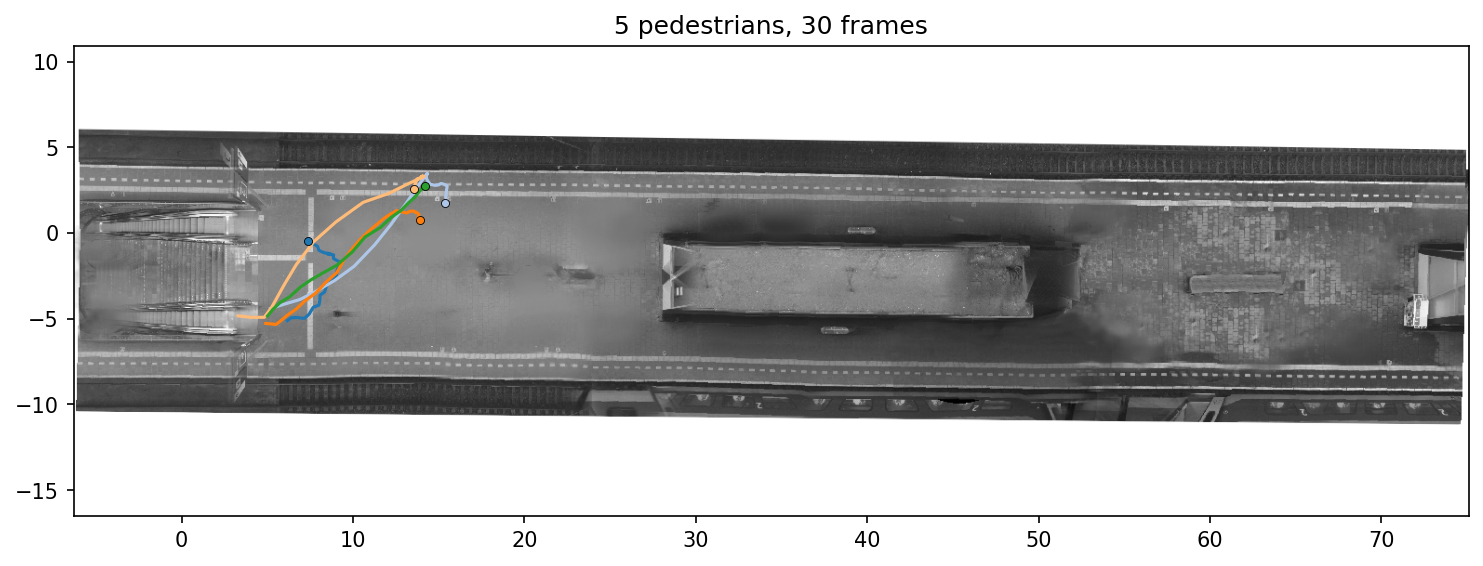

In [265]:
EXTENT = (-6.309, 75.091, -16.539, 10.909)  # (left, right, bottom, top) of the background image in metres


def plot_sample(sample, background_path="Eindhoven_centraal_platform_3_4.png", ax=None,
                cmap_name="tab20", figsize=(12, 4.5), dpi=150):
    """Plot all trajectories of one data sample on the station background.

    sample: (N, F, 2) positions of N pedestrians over F frames, as a numpy array or torch tensor.
    The x and y axes of the data are swapped to match the background image.
    Each pedestrian gets its own color; the dot marks the final position.
    """
    if isinstance(sample, torch.Tensor):
        sample = sample.detach().cpu().numpy()
    traj = np.asarray(sample)[..., [1, 0]]  # Swap x and y

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    else:
        fig = ax.figure

    ax.imshow(plt.imread(background_path), extent=EXTENT, origin="upper", zorder=0)
    ax.set_xlim(EXTENT[0], EXTENT[1])
    ax.set_ylim(EXTENT[2], EXTENT[3])

    cmap = plt.get_cmap(cmap_name)
    for i, t in enumerate(traj):
        color = cmap(i % cmap.N)
        ax.plot(t[:, 0], t[:, 1], color=color, lw=1.5, zorder=1)
        ax.scatter(t[-1, 0], t[-1, 1], color=color, s=15, edgecolors="black", linewidths=0.4, zorder=2)

    ax.set_title(f"{traj.shape[0]} pedestrians, {traj.shape[1]} frames")
    return fig, ax

plot_sample(dataset[0].x)
plt.show()

### EDA

In [286]:
# reused practical code

def plot_kinematics_summary(hist_quantities, hist_names, hist_colors,
                             line_quantities, line_names, line_colors,
                             model_labels=None, cols=3, hist_ranges=None, show_bands=True):
    def _as_tuple(x):
        return x if isinstance(x, tuple) else (x,)

    def _is_single_color(x):
        return (isinstance(x, tuple)
                and 3 <= len(x) <= 4
                and all(isinstance(e, (int, float, np.floating)) for e in x))

    def _as_color_tuple(x):
        if _is_single_color(x):
            return (x,)
        return _as_tuple(x)

    def _apply_ax_styles(ax):
        ax.tick_params(axis='both', labelsize=7)
        for spine in ax.spines.values():
            spine.set_color('#333333')
            spine.set_linewidth(1.5)

    def _model_colors(color, n_models):
        color_t = _as_color_tuple(color)
        if len(color_t) >= n_models:
            return color_t[:n_models]
        return color_t + tuple([color_t[-1]] * (n_models - len(color_t)))

    def _labels(n_models):
        if model_labels and len(model_labels) >= n_models:
            return model_labels[:n_models]
        return [None] * n_models

    def _filter_present(vals_t, color_t, labels_t):
        kept = [(v, c, l) for v, c, l in zip(vals_t, color_t, labels_t) if v is not None]
        if not kept:
            return (), (), []
        vs, cs, ls = zip(*kept)
        return vs, cs, list(ls)

    def _to_flat_array(v):
        if isinstance(v, (list, tuple)) and len(v) and isinstance(v[0], np.ndarray):
            v = np.concatenate([np.asarray(s).flatten() for s in v])
        v = np.asarray(v).flatten()
        return v[np.isfinite(v)]

    def _to_time_array(v):
        if isinstance(v, (list, tuple)) and len(v) and isinstance(v[0], np.ndarray):
            pieces = []
            for s in v:
                s = np.asarray(s)
                moved = np.moveaxis(s, 1, 0)
                pieces.append(moved.reshape(moved.shape[0], -1))
            return np.concatenate(pieces, axis=1)
        v = np.asarray(v)
        moved = np.moveaxis(v, 1, 0)
        return moved.reshape(moved.shape[0], -1)

    linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1))]
    hist_linestyles = ['--', '-.', ':', (0, (3, 1, 1, 1))]  # for outline models (index >= 1)

    # ---------------- Histogram grid ----------------
    n_hist = len(hist_quantities)
    hist_rows = math.ceil(n_hist / cols) if n_hist else 0
    n_line = len(line_quantities)
    line_rows = math.ceil(n_line / cols) if n_line else 0
    total_rows = hist_rows + line_rows

    fig, axs = plt.subplots(total_rows, cols,
                             figsize=(3.4 * cols, 3.1 * total_rows),
                             dpi=150, squeeze=False)

    for idx in range(hist_rows * cols):
        r, c = divmod(idx, cols)
        ax = axs[r][c]
        if idx >= n_hist:
            ax.axis('off')
            continue
        _apply_ax_styles(ax)
        vals, name, color = hist_quantities[idx], hist_names[idx], hist_colors[idx]
        vals_raw = _as_tuple(vals)
        color_raw = _model_colors(color, len(vals_raw))
        labels_raw = _labels(len(vals_raw))
        vals_t, color_t, labels_t = _filter_present(vals_raw, color_raw, labels_raw)
        n_models = len(vals_t)

        flat = [_to_flat_array(v) for v in vals_t]
        forced_range = hist_ranges[idx] if hist_ranges and idx < len(hist_ranges) else None
        if forced_range is not None:
            lo, hi = forced_range
        else:
            lo = min(np.quantile(v, 0.01) for v in flat)
            hi = max(np.quantile(v, 0.99) for v in flat)
        bins = np.linspace(lo, hi, 60)

        for i, (v, c_, lbl) in enumerate(zip(flat, color_t, labels_t)):
            label = f'μ = {np.mean(v):.2f}' if lbl is None else f'{lbl} μ = {np.mean(v):.2f}'
            if i == 0:
                fill_alpha = 0.85 if n_models == 1 else 0.5
                ax.hist(v, bins=bins, histtype='stepfilled', color=c_, alpha=fill_alpha,
                         edgecolor=c_, linewidth=1.3, zorder=2, label=label, density=True)
            else:
                ls = hist_linestyles[(i - 1) % len(hist_linestyles)]
                ax.hist(v, bins=bins, histtype='step', color=c_, linewidth=1.6,
                          zorder=3, label=label, density=True)
            # ax.axvline(np.mean(v), color=c_, linestyle='--', linewidth=0.8,
            #             zorder=4, label=label)

        ax.set_title(name, fontsize=11, fontweight='bold')
        ax.set_xlabel(name, fontsize=9)
        ax.set_ylabel('Density', fontsize=9)
        ax.legend(loc='best', fontsize=7, frameon=False)
        ax.grid(alpha=0.5, linestyle='--', linewidth=0.5, zorder=0)
        ax.spines[['top', 'right']].set_visible(False)

    if n_line:
        line_row = axs[hist_rows]
        n_models_fill_alpha = {1: 0.22, 2: 0.16}

        for idx in range(line_rows * cols):
            r, c = divmod(idx, cols)
            ax = line_row[c] if line_rows == 1 else axs[hist_rows + r][c]
            col = idx
            if col >= n_line:
                ax.axis('off')
                continue
            _apply_ax_styles(ax)
            vals, name, color = line_quantities[col], line_names[col], line_colors[col]
            vals_raw = _as_tuple(vals)
            color_raw = _model_colors(color, len(vals_raw))
            labels_raw = _labels(len(vals_raw))
            vals_t, color_t, labels_t = _filter_present(vals_raw, color_raw, labels_raw)
            n_models = len(vals_t)
            fill_alpha = n_models_fill_alpha.get(n_models, 0.10)

            for i, (arr, c_, lbl) in enumerate(zip(vals_t, color_t, labels_t)):
                arr = _to_time_array(arr)
                median = np.percentile(arr, 50, axis=1)
                q25 = np.percentile(arr, 25, axis=1)
                q75 = np.percentile(arr, 75, axis=1)
                t = np.arange(len(median))
                ls = linestyles[i % len(linestyles)]

                if show_bands:
                    ax.fill_between(t, q25, q75, color=c_, alpha=fill_alpha, linewidth=0, zorder=2)
                    ax.plot(t, q25, color=c_, linewidth=0.9, linestyle=ls, alpha=0.5, zorder=2)
                    ax.plot(t, q75, color=c_, linewidth=0.9, linestyle=ls, alpha=0.5, zorder=2)
                    
                ax.plot(t, median, color=c_, linewidth=2.4, zorder=3, label=lbl,
                         alpha=0.95, linestyle=ls)

            ax.set_title(f'{name} over Time', fontsize=11, fontweight='bold')
            ax.set_xlabel('Timestep', fontsize=9)
            ax.set_ylabel(name, fontsize=9)
            if any(labels_t):
                ax.legend(loc='best', fontsize=7, frameon=False)
            ax.grid(alpha=0.5, linestyle='--', linewidth=0.5, zorder=0)
            ax.spines[['top', 'right']].set_visible(False)

    fig.tight_layout(pad=0.5, h_pad=1.2)
    return fig, axs

# Use the ground truth positions for kinematic calculations
def calculate_kinematics(positions, dt, min_net_disp=0.5):
    velocities = np.gradient(positions, dt, axis=1)
    accelerations = np.gradient(velocities, dt, axis=1)
    vel_magnitudes = np.linalg.norm(velocities, axis=-1)
    acc_magnitudes = np.linalg.norm(accelerations, axis=-1)

    arc_lengths = np.sum(vel_magnitudes, axis=1) * dt
    net_displacement = np.linalg.norm(positions[:, -1] - positions[:, 0], axis=-1)
    tortuosity = np.where(net_displacement > min_net_disp, arc_lengths / np.maximum(net_displacement, 1e-6), np.nan)

    pairwise_dist = np.linalg.norm(positions[:, :, :, None, :] - positions[:, :, None, :, :], axis=-1)
    N = positions.shape[2]
    pairwise_dist[:, :, np.arange(N), np.arange(N)] = np.inf
    closest_distances = pairwise_dist.min(axis=-1)

    total_kinetic_energy = 0.5 * np.sum(vel_magnitudes ** 2, axis=-1)

    iu, ju = np.triu_indices(N, k=1)
    pairwise_dist_ij = pairwise_dist[:, :, iu, ju]

    return {"vel_magnitudes": vel_magnitudes, "acc_magnitudes": acc_magnitudes,
            "arc_lengths": arc_lengths, "net_displacement": net_displacement, "tortuosity": tortuosity,
            "closest_distances": closest_distances, "total_kinetic_energy": total_kinetic_energy, "distances": pairwise_dist_ij}

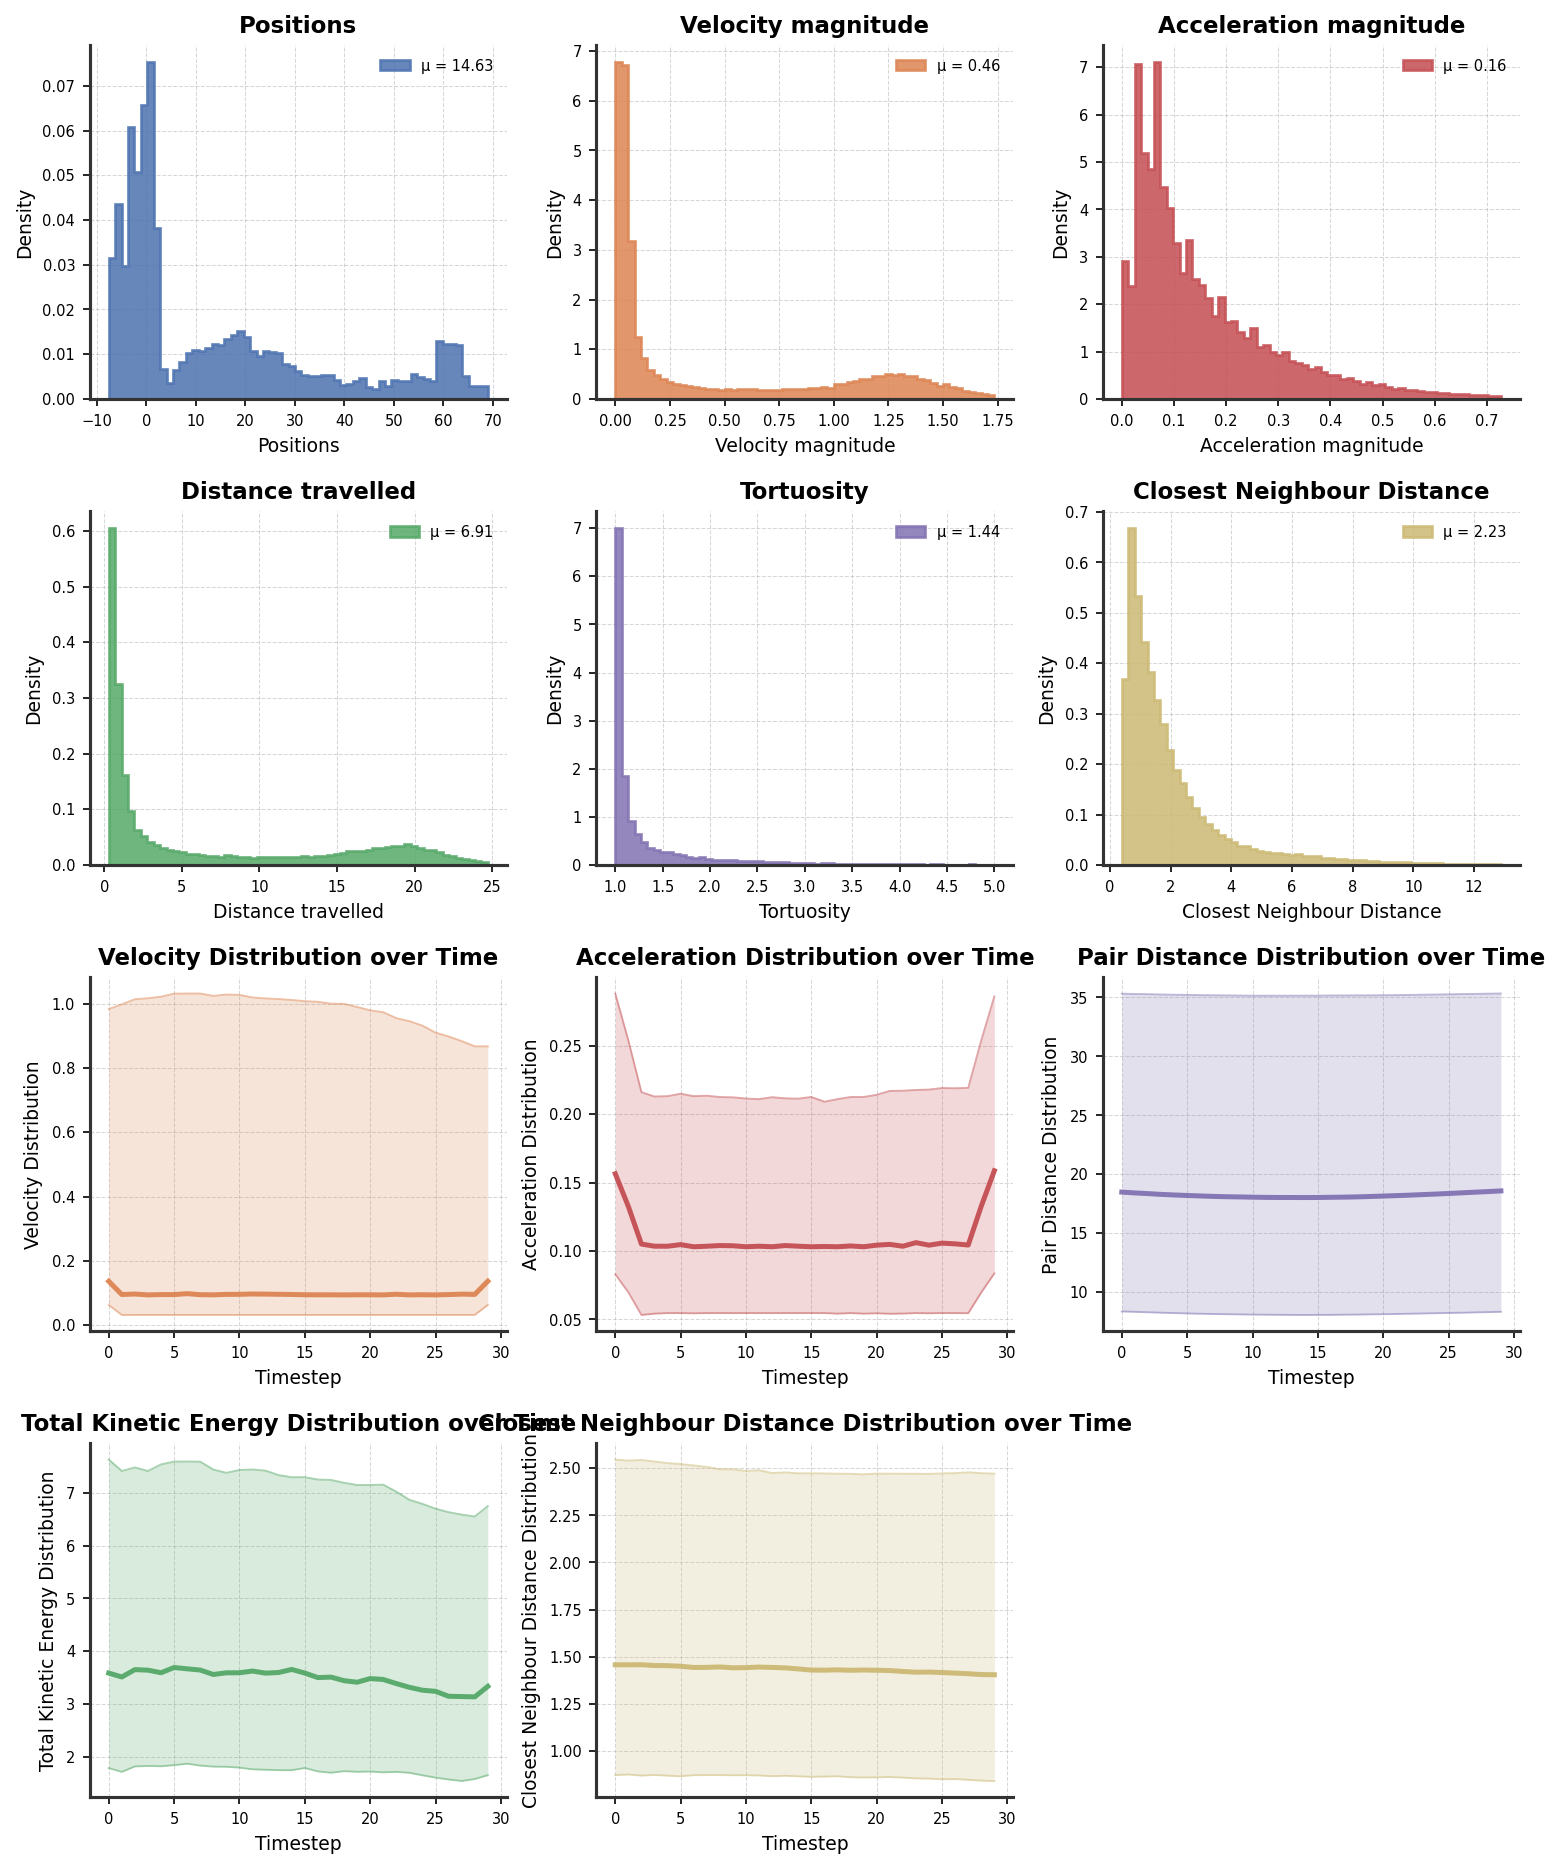

In [269]:
dt = 0.5  # Time step size

# Positions per scene: (1, #time_steps, #pedestrians, 2), N differs per scene so we keep a list
train_idx = data_module.train_data.indices[:2000]
positions = [dataset.raw_data[i].numpy()[None].transpose(0, 2, 1, 3) for i in train_idx]

kin = [calculate_kinematics(p, dt) for p in positions]
properties = {k: [d[k] for d in kin] for k in kin[0]}


hist_names = ['Positions', 'Velocity magnitude', 'Acceleration magnitude', 'Distance travelled', 'Tortuosity', 'Closest Neighbour Distance']
hist_values = [positions, properties['vel_magnitudes'], properties['acc_magnitudes'], properties['arc_lengths'], properties['tortuosity'], properties['closest_distances']]
hist_colors = ['#4C72B0', '#DD8452', '#C44E52', '#55A868', '#8172B2', '#CCB974']

line_names = ['Velocity Distribution', 'Acceleration Distribution', 'Pair Distance Distribution', 'Total Kinetic Energy Distribution', 'Closest Neighbour Distance Distribution']
line_values = [properties['vel_magnitudes'], properties['acc_magnitudes'], properties['distances'], properties['total_kinetic_energy'], properties['closest_distances']]
line_colors = ['#DD8452', '#C44E52', '#8172B2', '#55A868', '#CCB974']

%matplotlib inline
fig, axs = plot_kinematics_summary(hist_values, hist_names, hist_colors,
                                    line_values, line_names, line_colors, hist_ranges=[None, None, None, None, (1.0, 5.0), None])
fig.savefig("eda_kinematics.png", dpi=150, bbox_inches="tight")
plt.show()

## Model architecture

Your model must capture patterns over **space**, the interactions between pedestrians, and over **time**, how the motion of each pedestrian evolves over the frames. As discussed in Practical 4, message passing handles space but not time, and flattening all frames into an MLP ignores temporal order and locality. Design an architecture that handles both axes, for example message passing over pedestrians combined with convolutions or attention over time.

Use the same architecture, training budget and sampler for both models, so that the prior is the only difference between them.

In [ ]:
class NeuralMessagePassingLayer(nn.Module):
    def __init__(self, in_features, in_edge_features, hidden_dim, out_features):
        super().__init__()
        self.message_mlp = nn.Sequential(
            nn.Linear(2* in_features + in_edge_features, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
        )
        self.node_mlp = nn.Sequential(
            nn.Linear(in_features + hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, out_features),
        )

    def forward(self, x, edge_index, edge_attr):
        """
        x:          (B*N, in_features)
        edge_index: (2, B*E) where E is the number of edges
        edge_attr:  (B*E, in_edge_features) edge attributes
        """
        source_nodes, target_nodes = edge_index  
        messages = self.message_mlp(torch.cat([x[source_nodes], x[target_nodes], edge_attr], dim=-1))

        aggregated_messages = torch.zeros(x.size(0), messages.size(-1), device=x.device)
        aggregated_messages.index_reduce_(0, target_nodes, messages, reduce="mean", include_self=False)

        x = torch.cat([x, aggregated_messages], dim=-1)
        x = self.node_mlp(x)
    
        return x


class ConvDenoiseGNN(nn.Module):
    def __init__(self, tau_dim = 32, hidden_dim = 64, in_edge_features = 3):
        super().__init__()
        self.tau_dim = tau_dim
        self.in_edge_features = in_edge_features
        self.tau_proj = nn.Linear(tau_dim, hidden_dim)
        self.hidden_dim = hidden_dim
        self.x_tau_summary_MLP = nn.Sequential(nn.Linear(20*2, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, hidden_dim)) # 20, 2 to d

        self.x_tau_frame_MLP = nn.Sequential(nn.Linear(2, hidden_dim * 2), nn.SiLU(), nn.Linear(hidden_dim * 2, hidden_dim))
        self.frame_emb = nn.Embedding(20, hidden_dim)

        self.head = nn.Linear(hidden_dim, 2)

        #convolution is used to get locality, we also use positional encodings to make this even more aware to the model

        self.conv_enc = nn.Sequential(
            nn.Conv1d(4, hidden_dim, kernel_size=3), #turns sigmaN, 4, 9 into sigmaN, d, 7
            nn.SiLU(),
            nn.Conv1d(hidden_dim, hidden_dim, kernel_size=3), #5,
            nn.SiLU(),
            nn.Conv1d(hidden_dim, hidden_dim, kernel_size=3), #3,
            nn.SiLU(),
            nn.Conv1d(hidden_dim, hidden_dim, kernel_size=3) #1
        )

        self.conv_dec = nn.Sequential(
            nn.Conv1d(hidden_dim, hidden_dim, 3, padding = 1),
            nn.SiLU(),
            nn.Conv1d(hidden_dim, hidden_dim, 3, padding = 1),
            nn.SiLU(),
            nn.Conv1d(hidden_dim, hidden_dim, 3, padding = 1),
            nn.SiLU(),
            nn.Conv1d(hidden_dim, hidden_dim, 3, padding = 1)
        )

        self.message_passing1 = NeuralMessagePassingLayer(
            hidden_dim, in_edge_features, hidden_dim, hidden_dim
        )
        self.message_passing2 = NeuralMessagePassingLayer(
            hidden_dim, in_edge_features, hidden_dim, hidden_dim
        )


    def timestep_embedding(self, timesteps, dim, max_period=10000):
        """Create sinusoidal timestep embeddings."""
        half = dim // 2
        freqs = torch.exp(-math.log(max_period) * torch.arange(half, device=timesteps.device, dtype=torch.float32) / half)
        args = timesteps[:, None].float() * freqs[None]
        embedding = torch.cat([args.cos(), args.sin()], dim=-1)
        if dim % 2:
            embedding = F.pad(embedding, (0, 1))
        return embedding

    def forward(self, cond_in, tau, x_tau, edge_index, edge_attr):
        #encode flow time tau
        tau_emb = self.timestep_embedding(tau*1000, self.tau_dim)
        tau_emb = self.tau_proj(tau_emb)

        #encode x_tau of shape sigmaN, 20, 2 -> flatten into sigmaN, 40 -> sigmaN, d using a linear layer
        x_tau_sum = self.x_tau_summary_MLP(torch.flatten(x_tau, start_dim=1, end_dim=-1))

        #take cond_in, transpose and run it through self.conv_enc to get sigmaN, d
        cond_emb = self.conv_enc(torch.transpose(cond_in, 1, 2)).squeeze(-1)

        x = cond_emb + x_tau_sum + tau_emb

        x = self.message_passing1(x, edge_index, edge_attr)
        x = F.silu(x)
        x = self.message_passing2(x, edge_index, edge_attr)

        #encode sigmaN, 20, 2 into sigmaN, 20, d
        x_tau_frames = self.x_tau_frame_MLP(x_tau)

        #stack the GNN output and add x_tau_frames

        x = x.unsqueeze(1).repeat((1, 20, 1,)) + x_tau_frames + tau_emb.unsqueeze(1)

        #get positional encodings for the frames
        x = x + self.frame_emb(torch.arange(20, device=x_tau.device))

        #take result, stack/repeat, add x_tau_frames and add tau_emb again to all frames
        #then run through self.conv_dec and then through self.head
        x_dec = torch.transpose(self.conv_dec(torch.transpose(x, 1, 2)), 1, 2)
        output = self.head(x_dec)
        return output
        


In [275]:
class ProbabilisticTrajectoryModel(L.LightningModule):
    def __init__(self, model, stats, prior="gaussian", prior_std=1.0, gamma=1.0,
                 T_cond=10, T_total=30, dt=DT, denoising_steps=10, learning_rate=1e-3,
                 num_samples=10, return_all_steps=False):
        super().__init__()
        self.save_hyperparameters(ignore=["model"])
        self.model = model
        self.prior = prior #gaussian : N(0, sigma^2*I) damped : x0 = gamma^k * v_9 + sigma*epsilon...
        self.prior_std = prior_std
        self.gamma = gamma
        self.T_cond = T_cond
        self.K = T_total - T_cond
        self.dt = dt
        self.denoising_steps = denoising_steps
        self.learning_rate = learning_rate
        self.num_samples = num_samples
        self.return_all_steps = return_all_steps
        for name in ["pos_mean", "pos_std", "vel_mean", "vel_std"]:
            self.register_buffer(name, stats[name].clone().float())

    def prepare_batch(self, batch):
        x, H = batch.x, self.T_cond
        vel = (x[:, 1:] - x[:, :-1]) / self.dt
        pos_n = (x - self.pos_mean) / self.pos_std
        vel_n = (vel - self.vel_mean) / self.vel_std
        cond_in = torch.cat([pos_n[:, 1:H], vel_n[:, :H - 1]], dim=-1)
        x1 = vel_n[:, H - 1:]
        p_last = x[:, H - 1]
        return cond_in, x1, p_last #sigma,N T_cond-1, 4 then sigmaN, K, 2 then sigmaN, 2

    def sample_prior(self, shape, cond_in):
        noise = self.prior_std * torch.randn(shape, device=cond_in.device, dtype=cond_in.dtype)
        if self.prior == "gaussian":
            return noise
        if self.prior == "damped":
            v_last = cond_in[:, -1:, 2:4]
            k = torch.arange(1, shape[1] + 1, device=cond_in.device).view(1, -1, 1)
            return self.gamma ** k * v_last + noise
        raise ValueError(f"invalid prior setting {self.prior!r}")

    def forward(self, cond_in, tau, x_tau, edge_index, edge_attr):
        return self.model(cond_in, tau, x_tau, edge_index, edge_attr)

    def _step(self, batch):
        cond_in, x1, _ = self.prepare_batch(batch)
        tau = torch.rand(batch.num_graphs, device=x1.device)[batch.batch]
        x0 = self.sample_prior(x1.shape, cond_in)
        t = tau[:, None, None]
        x_tau = (1 - t) * x0 + t * x1
        u = x1 - x0
        v = self(cond_in, tau, x_tau, batch.edge_index, batch.edge_attr)
        return F.mse_loss(v, u)

    def training_step(self, batch, batch_idx):
        loss = self._step(batch)
        self.log("train_loss", loss, batch_size=batch.num_graphs, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        loss = self._step(batch)
        self.log("val_loss", loss, batch_size=batch.num_graphs, prog_bar=True)
        return loss

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=self.learning_rate)

    def predict_step(self, batch, batch_idx):
        trajs, vs = [], []
        for _ in range(self.num_samples):
            traj, v, mask = self._predict_one_sample(batch)
            trajs.append(traj if self.return_all_steps else traj[:, -1])
            if self.return_all_steps:
                vs.append(v)
        gt, _ = to_dense_batch(batch.x, batch.batch)
        out = {"traj": torch.stack(trajs, 1), "gt": gt, "mask": mask}
        if self.return_all_steps:
            out["v"] = torch.stack(vs, 1)
        return out

    @torch.no_grad()
    def _predict_one_sample(self, batch, denoising_step_override=None):
        cond_in, _, p_last = self.prepare_batch(batch)
        n, S, K = cond_in.size(0), self.denoising_steps, self.K
        if denoising_step_override:
            S = denoising_step_override
        taus = torch.linspace(0.0, 1.0, S + 1, device=cond_in.device)

        steps = torch.zeros(n, S + 1, K, 2, device=cond_in.device)
        v_vectors = torch.zeros(n, S, K, 2, device=cond_in.device)
        steps[:, 0] = self.sample_prior((n, K, 2), cond_in)
        for i in range(S):
            tau = taus[i].expand(n)
            v = self(cond_in, tau, steps[:, i], batch.edge_index, batch.edge_attr)
            v_vectors[:, i] = v
            steps[:, i + 1] = steps[:, i] + (taus[i + 1] - taus[i]) * v

        vel = steps * self.vel_std + self.vel_mean
        pred_pos = p_last[:, None, None, :] + self.dt * torch.cumsum(vel, dim=2)
        obs_pos = batch.x[:, None, :self.T_cond].expand(-1, S + 1, -1, -1)
        traj = torch.cat([obs_pos, pred_pos], dim=2)

        traj, mask = to_dense_batch(traj, batch.batch)
        v_vectors, _ = to_dense_batch(v_vectors, batch.batch)
        return traj.transpose(1, 2), v_vectors.transpose(1, 2), mask

class LossHistory(L.Callback):
    def __init__(self):
        self.train_loss, self.val_loss = [], []
    def on_train_epoch_end(self, trainer, pl_module):
        self.train_loss.append(trainer.callback_metrics.get("train_loss").item())
    def on_validation_epoch_end(self, trainer, pl_module):
        self.val_loss.append(trainer.callback_metrics.get("val_loss").item())

def plot_loss_curves(train_loss, val_loss, title="Loss Curves", save_path=None):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(train_loss, label="Train loss (epoch mean)", color="tab:blue")
    ax.plot(val_loss, label="Validation loss", color="tab:orange")
    ax.set(title=title, xlabel="Epoch", ylabel="Flow matching MSE")
    ax.legend(); ax.grid(alpha=0.5)
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

In [276]:
H, K = data_module.T_cond, 30 - data_module.T_cond
stats = data_module.stats

COMMON = dict(stats=stats, T_cond=H, dt=DT, denoising_steps=20, learning_rate=5e-4, num_samples=20)
PRIOR_STD = 1.0  # only changing the mean not the var

train_samples = [data_module.train_data.dataset.raw_data[i] for i in data_module.train_data.indices]
v_obs = torch.cat([(s[:, 1:H] - s[:, :H - 1]) / dt for s in train_samples])
v_obs = (v_obs - stats["vel_mean"]) / stats["vel_std"]
gamma = ((v_obs[:, 1:] * v_obs[:, :-1]).sum() / (v_obs[:, :-1] ** 2).sum()).item()
print(f"gamma = {gamma}  ->  after {K} frames, {gamma ** K} of last velocity is in there")

def make_trainer(callbacks):
    return L.Trainer(max_epochs=20, accelerator="auto", callbacks=callbacks,
                     limit_train_batches=300, limit_val_batches=100,
                     logger=False, enable_checkpointing=False)

gamma = 0.7974531054496765  ->  after 20 frames, 0.01081690641619483 of last velocity is in there


## Part I: Uninformed Gaussian prior

Train a conditional flow matching model that generates the velocities of frames 10 to 29, conditioned on frames 0 to 9, using the independent coupling

$$\pi(x_0, x_1 \mid c) = p_0(x_0)\,p_1(x_1 \mid c), \qquad p_0 = \mathcal{N}(0, \sigma^2 I).$$

All 20 frames are generated in a single model call. Positions are recovered by summing the generated velocities, starting from the last observed position.

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type           | Params | Mode  | FLOPs
---------------------------------------------------------
0 | model | ConvDenoiseGNN | 156 K  | train | 0    
---------------------------------------------------------
156 K     Trainable params
0         Non-trainable params
156 K     Total params
0.625     Total estimated model params size (MB)
46        Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

c:\Users\Saber\.conda\envs\DEEPLEARNING\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=23` in the `DataLoader` to improve performance.
c:\Users\Saber\.conda\envs\DEEPLEARNING\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=23` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=20` reached.
`weights_only` was not set, defaulting to `False`.


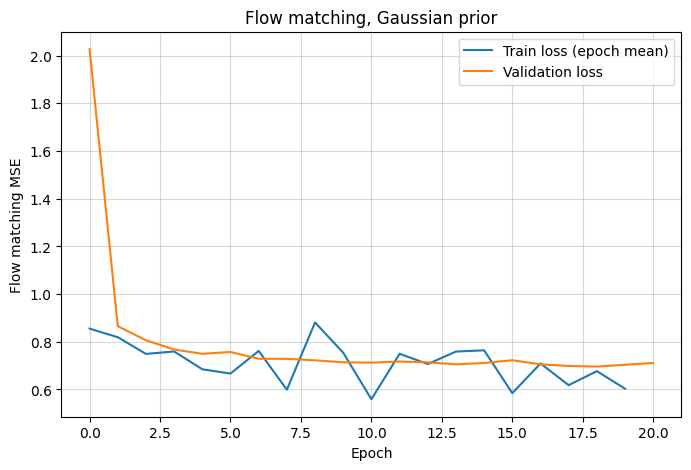

In [277]:
L.seed_everything(SEED)
gaussian_model = ProbabilisticTrajectoryModel(model=ConvDenoiseGNN(), prior="gaussian",
                                              prior_std=PRIOR_STD, **COMMON)
loss_history_gaussian = LossHistory()
trainer_gaussian = make_trainer([loss_history_gaussian])
trainer_gaussian.fit(gaussian_model, datamodule=data_module)
trainer_gaussian.save_checkpoint("flow_gaussian_prior.ckpt")

plot_loss_curves(loss_history_gaussian.train_loss, loss_history_gaussian.val_loss,
                 title="Flow matching, Gaussian prior", save_path=FIG_DIR / "loss_gaussian.png")

## Part II: Informed prior

Train a second model using a data dependent coupling

$$\pi(x_0, x_1 \mid c) = p_0(x_0 \mid c)\,p_1(x_1 \mid c).$$

The prior may only use the observed frames 0 to 9, so that $x_0 \perp x_1 \mid c$. It must remain stochastic and be sampled in the same way during training and inference.

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name  | Type           | Params | Mode  | FLOPs
---------------------------------------------------------
0 | model | ConvDenoiseGNN | 156 K  | train | 0    
---------------------------------------------------------
156 K     Trainable params
0         Non-trainable params
156 K     Total params
0.625     Total estimated model params size (MB)
46        Modules in train mode
0         Modules in eval mode
0         Total Flops


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=20` reached.
`weights_only` was not set, defaulting to `False`.


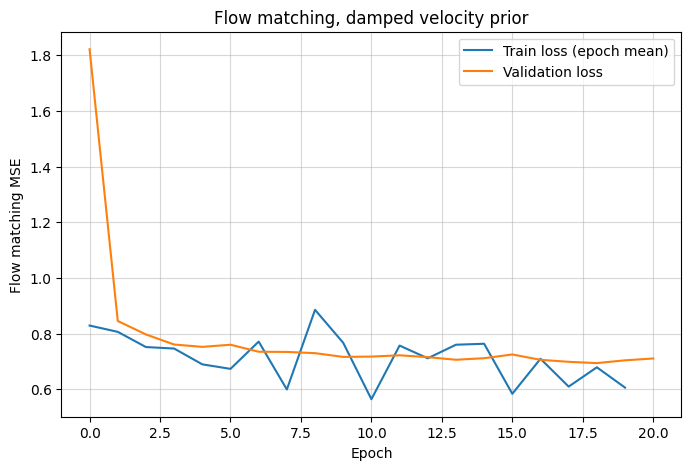

In [278]:
L.seed_everything(SEED)
damped_model = ProbabilisticTrajectoryModel(model=ConvDenoiseGNN(), prior="damped", gamma=gamma,
                                            prior_std=PRIOR_STD, **COMMON)
loss_history_damped = LossHistory()
trainer_damped = make_trainer([loss_history_damped])
trainer_damped.fit(damped_model, datamodule=data_module)
trainer_damped.save_checkpoint("flow_damped_prior.ckpt")

plot_loss_curves(loss_history_damped.train_loss, loss_history_damped.val_loss,
                 title="Flow matching, damped velocity prior", save_path=FIG_DIR / "loss_damped.png")

#reload:
# m = ProbabilisticTrajectoryModel.load_from_checkpoint("flow_damped_prior.ckpt", model=ConvDenoiseGNN(), stats=stats)

## Evaluation

For every test sample, generate $M = 20$ futures with each model. All metrics are computed on frames 10 to 29 only.

**Pointwise metrics.** Report ADE, FDE, $\text{min}_{20}$ ADE and $\text{min}_{20}$ FDE. ADE and FDE are averaged over all pedestrians, samples and generated futures. For the $\text{min}_{20}$ metrics, the best future is selected per data sample based on the error averaged over all its pedestrians, not per pedestrian.

**Distributional metrics.** Plot histogram densities of the ground truth and both models for velocity magnitude, acceleration magnitude, tortuosity and distance to the closest neighbour within the same frame.

The exact definitions are given in the evaluation section of the assignment PDF. You are of course allowed to use code from the practicals

In [ ]:
def evaluate_rollouts(rollouts, H, dt, n_futures_kin=5):
    keys = ["vel_magnitudes", "acc_magnitudes", "arc_lengths", "tortuosity", "closest_distances", "total_kinetic_energy"]
    ade, fde = [], []
    pred_kin, gt_kin = {k: [] for k in keys}, {k: [] for k in keys}
    pred_pos, gt_pos, de_future = [], [], []

    for r in rollouts:
        traj, gt, mask = r["traj"].cpu(), r["gt"].cpu(), r["mask"].cpu()
        for b in range(traj.shape[0]):
            n = int(mask[b].sum())
            p = traj[b, :, :n].numpy()
            g = gt[b, :n].numpy()

            de = np.linalg.norm(p - g[None], axis=-1)
            ade.append(de[:, :, H:].mean(axis=(1, 2)))
            fde.append(de[:, :, -1].mean(axis=1))

            pk = p[:n_futures_kin, :, H:].transpose(0, 2, 1, 3)
            gk = g[None, :, H:].transpose(0, 2, 1, 3)
            kp, kg = calculate_kinematics(pk, dt), calculate_kinematics(gk, dt)
            for k in keys:
                pred_kin[k].append(kp[k].astype(np.float32))
                gt_kin[k].append(kg[k].astype(np.float32))
            pred_pos.append(pk); gt_pos.append(gk)
            de_future.append(de[:n_futures_kin, :, H:].transpose(0, 2, 1).astype(np.float32))  # (m, K, N)

    return dict(ade=np.stack(ade), fde=np.stack(fde), pred_kin=pred_kin, gt_kin=gt_kin,
                pred_pos=pred_pos, gt_pos=gt_pos, de=de_future)


def report(name, ade, fde):
    M = ade.shape[1]
    print(f"{name:28s} ADE: {ade.mean():.4f}  FDE: {fde.mean():.4f}  "
          f"min{M} ADE: {ade.min(1).mean():.4f}  min{M} FDE: {fde.min(1).mean():.4f}")


rollouts_gaussian = trainer_gaussian.predict(gaussian_model, datamodule=data_module)
ev_gaussian = evaluate_rollouts(rollouts_gaussian, H, dt)
del rollouts_gaussian; gc.collect()

rollouts_damped = trainer_damped.predict(damped_model, datamodule=data_module)
ev_damped = evaluate_rollouts(rollouts_damped, H, dt)
del rollouts_damped; gc.collect()

report("Flow (Gaussian prior)", ev_gaussian["ade"], ev_gaussian["fde"])
report("Flow (damped velocity prior)", ev_damped["ade"], ev_damped["fde"])

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
c:\Users\Saber\.conda\envs\DEEPLEARNING\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=23` in the `DataLoader` to improve performance.


Predicting: |          | 0/? [00:00<?, ?it/s]

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

Flow (Gaussian prior)        ADE: 0.9563  FDE: 1.9175  min20 ADE: 0.7083  min20 FDE: 1.3472
Flow (damped velocity prior) ADE: 0.9491  FDE: 1.8928  min20 ADE: 0.7024  min20 FDE: 1.3254


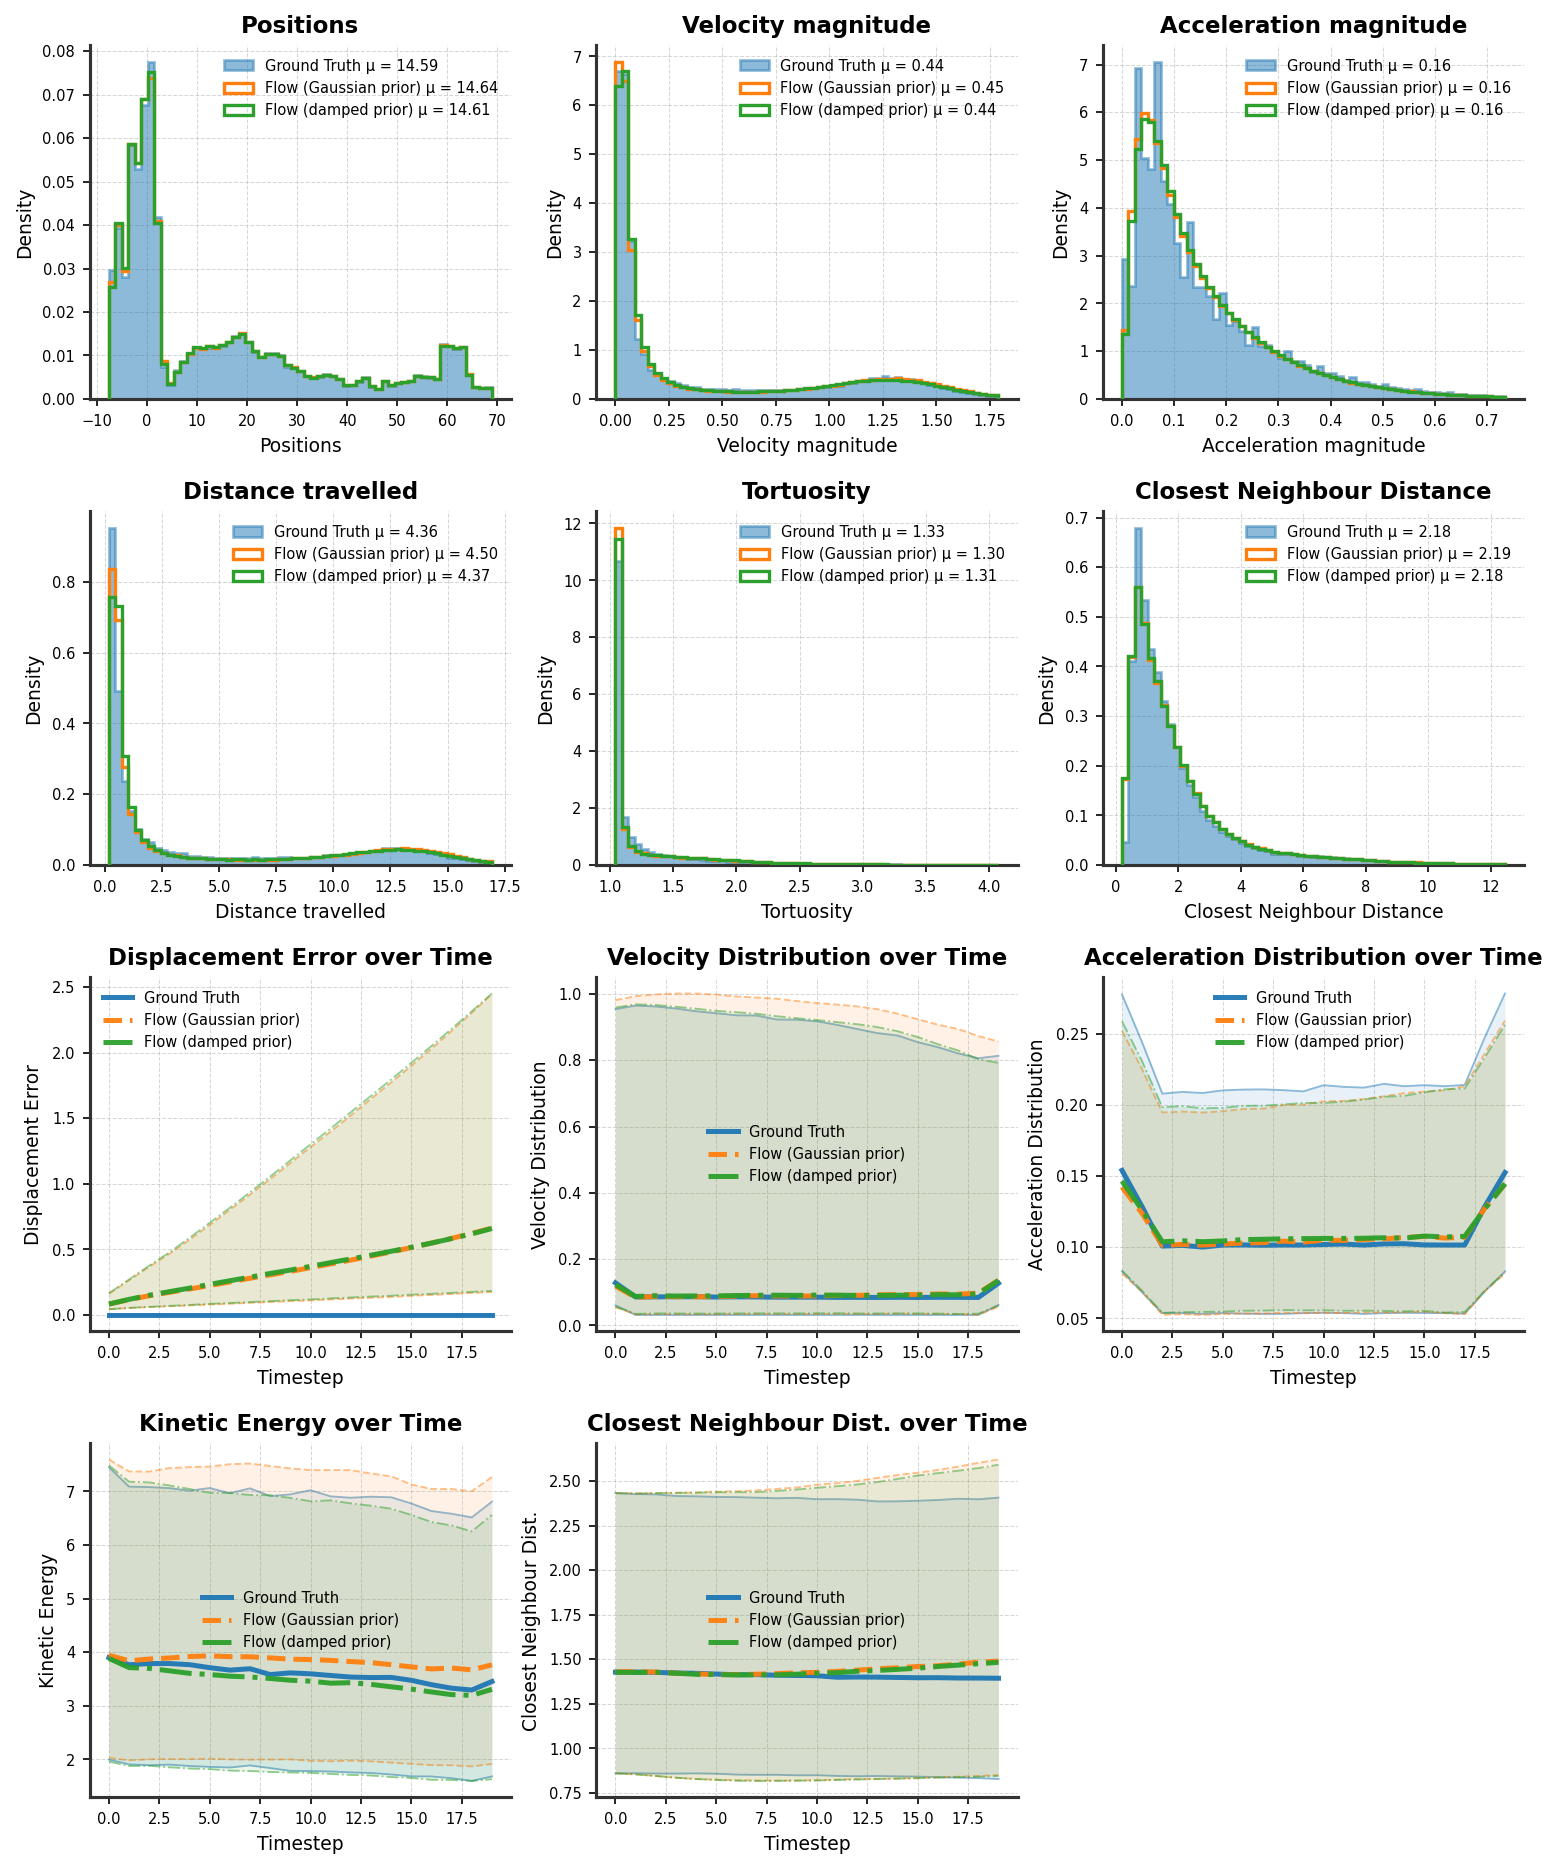

In [285]:
gk, pg, pd_ = ev_gaussian["gt_kin"], ev_gaussian["pred_kin"], ev_damped["pred_kin"]
cmap = plt.get_cmap("tab10")
colors = (cmap(0), cmap(1), cmap(2))

hist_names = ["Positions", "Velocity magnitude", "Acceleration magnitude", "Distance travelled", "Tortuosity", "Closest Neighbour Distance"]
hist_values = [(ev_gaussian["gt_pos"], ev_gaussian["pred_pos"], ev_damped["pred_pos"]),
               (gk["vel_magnitudes"], pg["vel_magnitudes"], pd_["vel_magnitudes"]),
               (gk["acc_magnitudes"], pg["acc_magnitudes"], pd_["acc_magnitudes"]),
               (gk["arc_lengths"], pg["arc_lengths"], pd_["arc_lengths"]),
               (gk["tortuosity"], pg["tortuosity"], pd_["tortuosity"]),
               (gk["closest_distances"], pg["closest_distances"], pd_["closest_distances"])]

line_names = ["Displacement Error", "Velocity Distribution", "Acceleration Distribution", "Kinetic Energy", "Closest Neighbour Dist."]
line_values = [([np.zeros((1, K, 1), np.float32)], ev_gaussian["de"], ev_damped["de"]),
               (gk["vel_magnitudes"], pg["vel_magnitudes"], pd_["vel_magnitudes"]),
               (gk["acc_magnitudes"], pg["acc_magnitudes"], pd_["acc_magnitudes"]),
               (gk["total_kinetic_energy"], pg["total_kinetic_energy"], pd_["total_kinetic_energy"]),
               (gk["closest_distances"], pg["closest_distances"], pd_["closest_distances"])]

%matplotlib inline
fig, axs = plot_kinematics_summary(hist_values, hist_names, [colors] * len(hist_names),
                        line_values, line_names, [colors] * len(line_names),
                        model_labels=["Ground Truth", "Flow (Gaussian prior)", "Flow (damped prior)"])
fig.savefig("pred_kinematics.png", dpi=150, bbox_inches="tight")
plt.show()

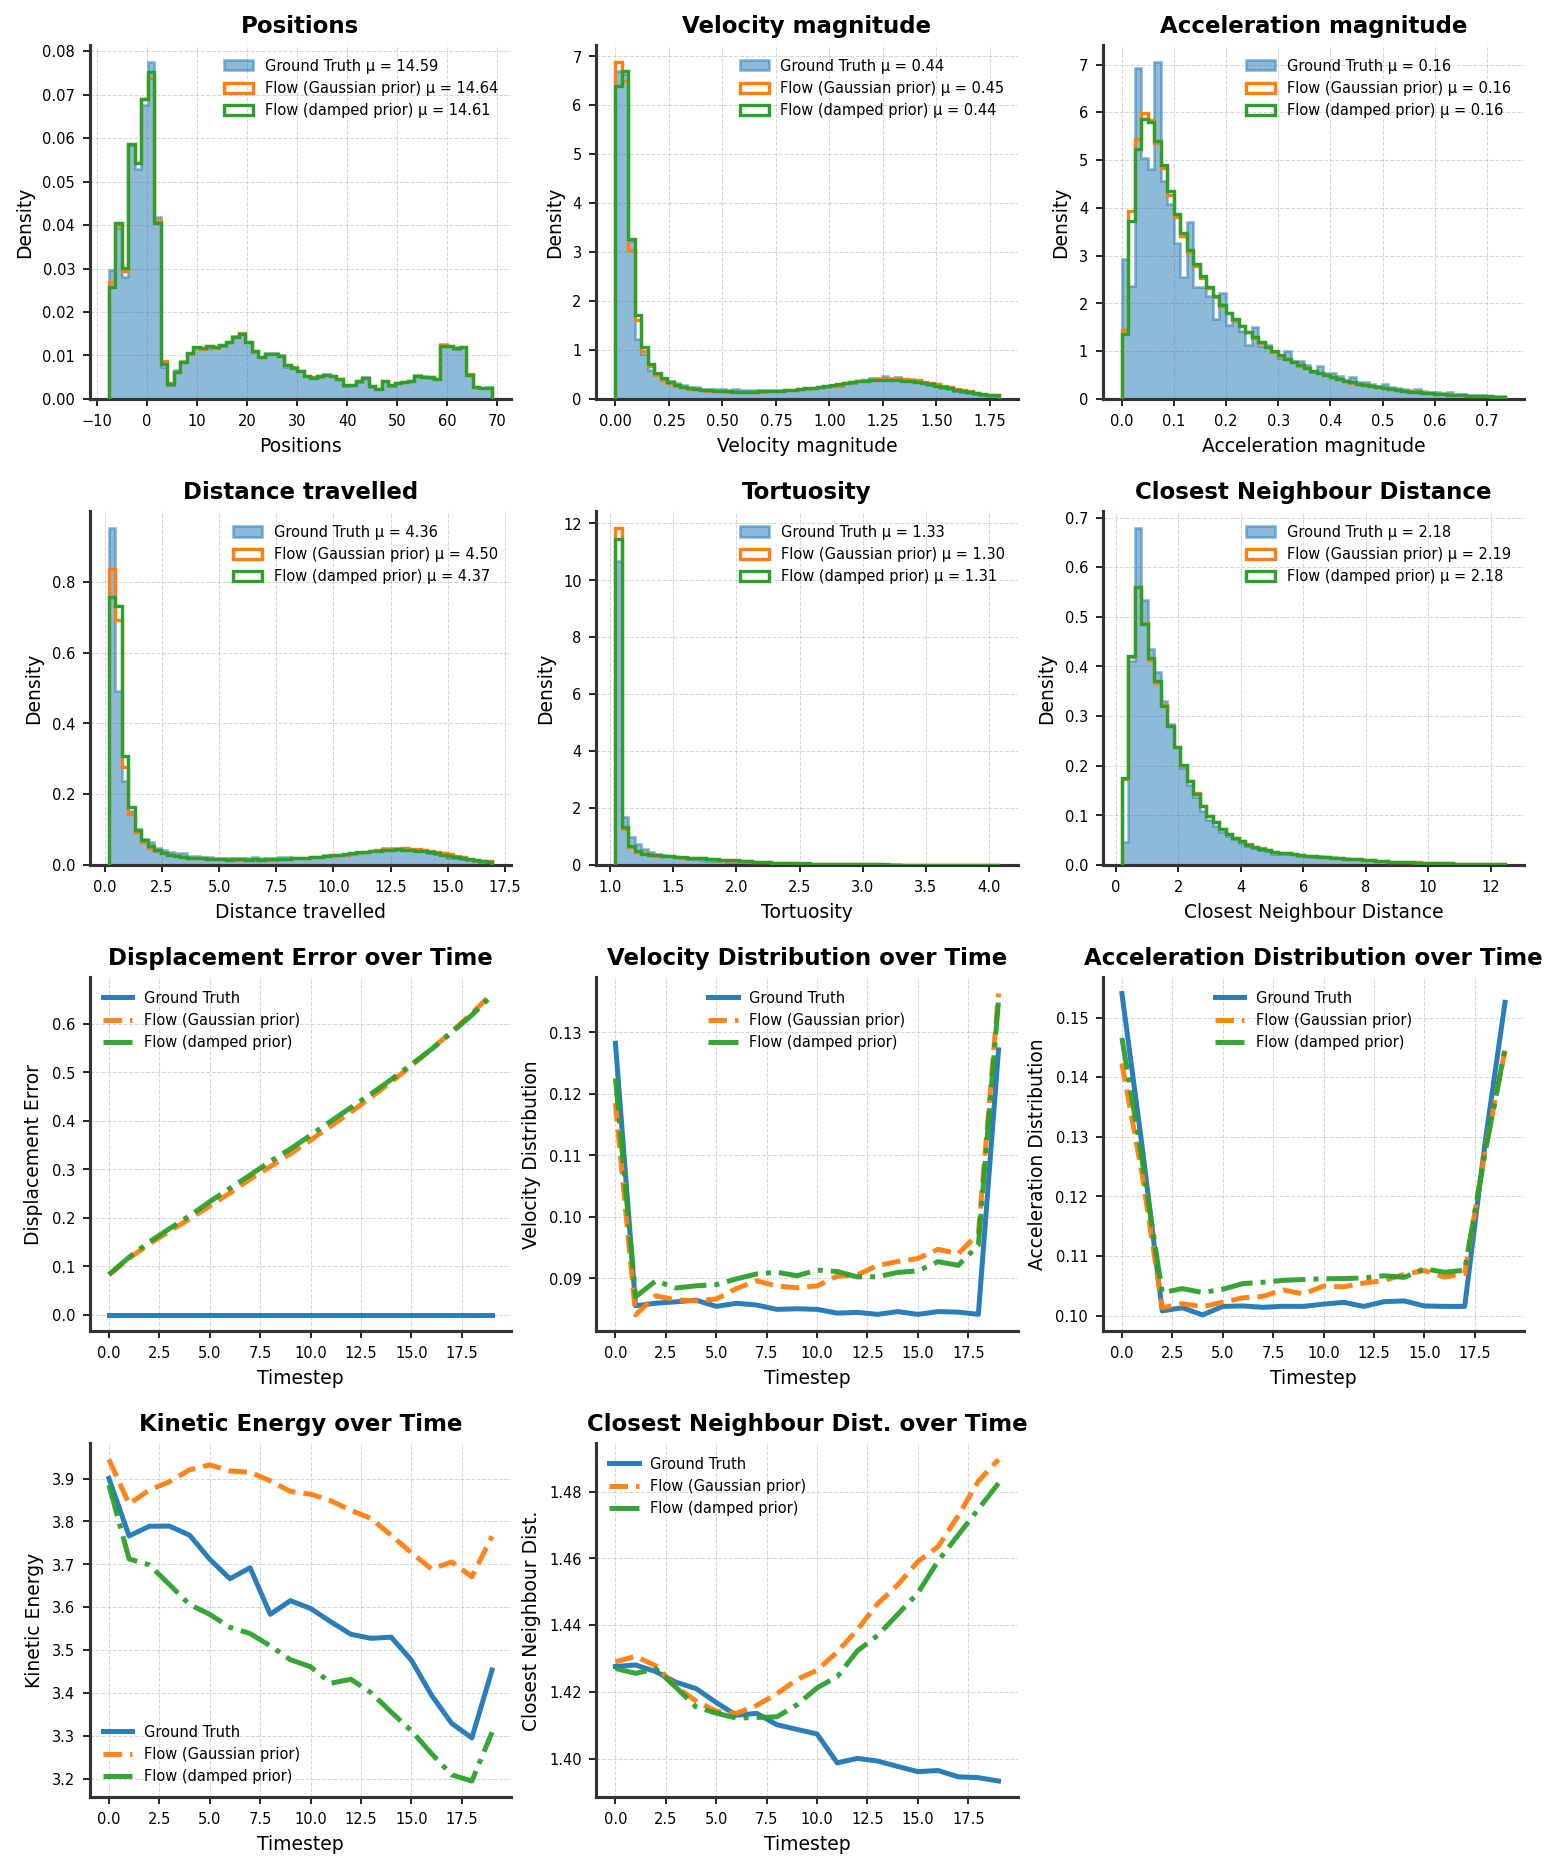

In [289]:
# the enormous error bounds tend to make it hard to read the graphs
fig, axs = plot_kinematics_summary(hist_values, hist_names, [colors] * len(hist_names),
                        line_values, line_names, [colors] * len(line_names),
                        model_labels=["Ground Truth", "Flow (Gaussian prior)", "Flow (damped prior)"], show_bands=False)
fig.savefig("pred_kinematics_no_bands.png", dpi=150, bbox_inches="tight")
plt.show()

### Conclusion

Small test on smaller euler steps for the informed prior

In [284]:
import pandas as pd

#The informed prior should in theory do better when the euler steps are smaller.
def ade_vs_steps(model, steps_list, max_batches=30):
    model.eval().to("cuda" if torch.cuda.is_available() else "cpu")
    out = {}
    for S in steps_list:
        errs = []
        for i, batch in enumerate(data_module.predict_dataloader()):
            if i >= max_batches: break
            batch = batch.to(model.device)
            traj, _, mask = model._predict_one_sample(batch, denoising_step_override=S)
            pred = traj[:, -1]
            gt, _ = to_dense_batch(batch.x, batch.batch)
            err = (pred[:, :, H:] - gt[:, :, H:]).norm(dim=-1).mean(-1)
            errs.append(err[mask].cpu())
        out[S] = torch.cat(errs).mean().item()
    return out

steps_list = [1, 2, 5, 10, 20]
res = pd.DataFrame({"Gaussian prior": ade_vs_steps(gaussian_model, steps_list),
                    "Damped velocity prior": ade_vs_steps(damped_model, steps_list)}).rename_axis("Euler steps").round(4)
print(res.to_markdown())

|   Euler steps |   Gaussian prior |   Damped velocity prior |
|--------------:|-----------------:|------------------------:|
|             1 |           0.8424 |                  0.7774 |
|             2 |           0.7655 |                  0.7498 |
|             5 |           0.8441 |                  0.8424 |
|            10 |           0.8909 |                  0.8908 |
|            20 |           0.9257 |                  0.9192 |
